<a href="https://colab.research.google.com/github/AMIRTHA192/ITA0601-ML/blob/main/lab_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Cluster Labels:
[1 2 0 2 1 2 0 2 2 0 0 1 1 0 0 1 1 0 1 1 0 1 1 0 0 0 2 1 1 1 1 2 2 1 0 0 0
 0 2 2 1 0 2 0 0 2 1 1 1 2 2 2 0 1 1 1 0 0 2 0 1 2 1 2 1 1 2 1 2 2 2 1 1 0
 2 1 2 1 2 2 0 2 0 1 0 0 0 2 0 2 2 2 0 2 0 0 0 2 1 0]

Cluster Means:
[[-2.66780392  8.93576069]
 [-6.95170962 -6.67621669]
 [ 4.49951001  1.93892013]]


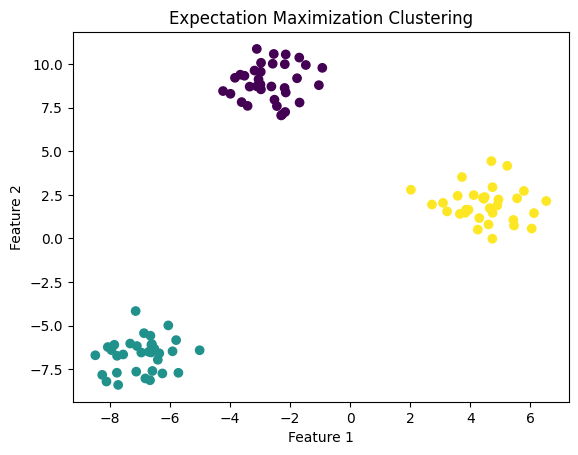

In [1]:
# Import libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture
from sklearn.datasets import make_blobs

# Create sample dataset
X, y = make_blobs(
    n_samples=100,
    centers=3,
    random_state=42
)

# Create EM model
model = GaussianMixture(n_components=3, random_state=42)

# Train model using EM algorithm
model.fit(X)

# Predict clusters
y_pred = model.predict(X)

# Display results
print("Cluster Labels:")
print(y_pred)

print("\nCluster Means:")
print(model.means_)

# Plot clusters
plt.scatter(X[:, 0], X[:, 1], c=y_pred, cmap='viridis')
plt.title("Expectation Maximization Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [2]:
# Import libraries
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

# Create dataset
data = {
    'Age': [22, 25, 30, 35, 40, 45, 50, 55, 28, 32,
            38, 42, 48, 52, 60, 27, 33, 39, 46, 58],
    'Income': [20000, 25000, 30000, 45000, 50000,
               60000, 70000, 80000, 28000, 35000,
               48000, 55000, 65000, 75000, 90000,
               22000, 40000, 52000, 68000, 85000],
    'Debt': [15000, 18000, 20000, 12000, 10000,
             15000, 12000, 10000, 22000, 18000,
             14000, 13000, 11000, 9000, 8000,
             20000, 16000, 12000, 10000, 7000],
    'Credit_Score': [
        'Poor', 'Poor', 'Average', 'Average', 'Good',
        'Good', 'Good', 'Excellent', 'Poor', 'Average',
        'Average', 'Good', 'Good', 'Excellent', 'Excellent',
        'Poor', 'Average', 'Good', 'Good', 'Excellent'
    ]
}

df = pd.DataFrame(data)

# Input and output
X = df[['Age', 'Income', 'Debt']]
y = df['Credit_Score']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Create model
model = RandomForestClassifier(n_estimators=100, random_state=42)

# Train model
model.fit(X_train, y_train)

# Predict output
y_pred = model.predict(X_test)

# Display accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

# Display confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Predict new credit score
new_customer = pd.DataFrame(
    [[30, 40000, 15000]],
    columns=['Age', 'Income', 'Debt']
)

prediction = model.predict(new_customer)

print("\nPredicted Credit Score:", prediction[0])

Accuracy: 0.75

Confusion Matrix:
[[0 0 1 0]
 [0 1 0 0]
 [0 0 1 0]
 [0 0 0 1]]

Predicted Credit Score: Average


In [3]:
# Import libraries
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.preprocessing import StandardScaler

# Load Iris dataset
iris = load_iris()

X = iris.data
y = iris.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Standardize data
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Create KNN model
model = KNeighborsClassifier(n_neighbors=3)

# Train model
model.fit(X_train, y_train)

# Predict output
y_pred = model.predict(X_test)

# Display accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

# Display confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Predict new flower
new_flower = [[5.1, 3.5, 1.4, 0.2]]

new_flower = scaler.transform(new_flower)

prediction = model.predict(new_flower)

print("\nPredicted Flower:", iris.target_names[prediction[0]])

Accuracy: 1.0

Confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]

Predicted Flower: setosa
